# Ultr4rick RP2350B DSP firmware — step-by-step example

Targets the **`-DDSP`** firmware build (see `../firmware/` and `../firmware/PINMAP.md`). Run the
cells top to bottom.

Shows the **raw text replies from the Pico** (parameters + per-stage DSP µs
times) alongside the decoded captures, **arms the pulser from the start**, covers
**raw / Hilbert-envelope / A-law**, runs the DSP **self-test**, checks the
**pulser order**, transmits/receives on **mux elements 2 and 4**, and **saves every capture to files** (`captures/<name>/`:
`<payload>.npy`, `header.json`, `status.txt`).

Requires: `pyserial`, `numpy`, `matplotlib`.

## 1. Imports

In [78]:
%matplotlib inline
import os, re, json, dataclasses
import numpy as np
import matplotlib.pyplot as plt
from ultr4rick.device import Ultr4rick
from ultr4rick import dsp

## 2. Connect

`PORT = None` auto-detects the USB-CDC port.

In [79]:
PORT = None
probe = Ultr4rick(port=PORT, verbose=False)

Device on /dev/ttyACM0
Firmware 0.1.15 - library 0.1.13


## 3. Version

In [80]:
print(probe.version()['raw'])

ultr4rick firmware v0.1.15
changes: Run from SRAM (copy_to_ram): DSP time no longer depends on flash layout; envelope 13.4-20 ms -> 6.55 ms, worst with A-law 7.3 ms. ~270 KB SRAM used.
board:   ultr4rick (RP2350B)
mux:     enabled (MAX14866)
build:   5c2852c-dirty
release: https://github.com/kelu124/ultr4rick/releases/tag/fw-v0.1.15



## 4. Status

The Pico's exact `status` line, then a readable breakdown (parameters +
per-stage DSP µs). Only works on a DSP build.

In [81]:
st = probe.status()
print('Pico reply:')
print(' ', st['raw'])
print()
print(dsp.describe_status(st))

Pico reply:
  OK board=ultr4rick package=RP2350B firmware=0.1.15 dsp_backend=f32-rfft-hilbert samples=4096 sample_rate=60000000 pulser=armed pulse=96/6000/96/neg-first dac=50 scale=512.000 stream=off/0 drops=0 stages_us=533/2265/148/2568/1038/0 dsp_us=6553 worst_us=7322 performance=over-budget envelope_max_rate=50 alaw_max_rate=70 cmsis=1.17.0 led=ok

ultr4rick status
  board/package    ultr4rick / RP2350B
  firmware         0.1.15
  dsp backend      f32-rfft-hilbert
  cmsis-dsp        1.17.0
  acquisition      4096 samples @ 60 MS/s
  pulser           armed
  pulse (ns)       neg 96 / damp 6000 / pos 96, neg-first
  dac / scale      50 / 512.0
  stream           off @ 0 Hz
  dropped frames   0
  DSP stage times (us):
      preprocess   533
      forward_fft  2265
      mask         148
      inverse_fft  2568
      magnitude    1038
      alaw         0
  dsp_us / worst   6553 / 7322 (over-budget)
  max rates (Hz)   envelope 50, alaw 70


## 5. Commands (`help`)

In [82]:
def send(cmd, wait=0.4):
    """Send a text command, print and return the Pico's reply. Do NOT use for
    commands that stream binary frames (selftest / captures)."""
    probe.ser.write((cmd + '\n').encode('ascii'))
    reply = ''.join(b.decode('utf-8', 'replace') for b in probe.sread()).strip()
    print(cmd, '->', reply)
    return reply

send('help')

help -> OK commands=status|help|version|reboot-dfu|pulser arm|pulser disarm|pulse config <negative_ns> <damp_ns> <positive_ns> <neg-first|pos-first>|dac write <0..1023>|dsp scale <reference>|dsp selftest|acq <raw|envelope|alaw>|read_raw|read_fft|stream start <raw|envelope|alaw> <rate_hz>|stream stop|write mux <hex>|set mux|clear mux|start acq|read


'OK commands=status|help|version|reboot-dfu|pulser arm|pulser disarm|pulse config <negative_ns> <damp_ns> <positive_ns> <neg-first|pos-first>|dac write <0..1023>|dsp scale <reference>|dsp selftest|acq <raw|envelope|alaw>|read_raw|read_fft|stream start <raw|envelope|alaw> <rate_hz>|stream stop|write mux <hex>|set mux|clear mux|start acq|read'

## 6. Set gain and ARM the pulser (from the start)

The pulser is armed here so **every capture below transmits**. The DSP build's
gain command is `dac write <n>` (0..1023).

In [83]:
GAIN = 200            # TGC DAC value 0..1023
send(f'dac write {GAIN}')
send('dsp scale 512')                       # A-law full-scale reference (ADC counts)
send('pulse config 96 6000 96 neg-first')   # neg/damp/pos ns, order
send('pulser arm')

dac write 200 -> OK dac=200
dsp scale 512 -> OK scale=512.000
pulse config 96 6000 96 neg-first -> OK pulse=96/6000/96/neg-first
pulser arm -> OK pulser armed


'OK pulser armed'

## 7. Capture helper (saves to files)

`grab(payload, name)` captures one frame, prints the Pico reply + header,
**saves** `data/dsp_captures/<name>/<payload>.npy` + `header.json` + `status.txt`, and
returns `(frame, samples)`.

In [84]:
CAPT = 'data/dsp_captures'

def grab(payload, name):
    frame = probe.capture(payload)          # 'raw' | 'envelope' | 'alaw'
    s = frame.samples()
    h = frame.header
    print('Pico reply:', probe.last_reply)
    print('  header: samples=%d bytes=%d dc_mean=%.1f envelope_peak=%.1f seq=%d'
          % (h.sample_count, h.payload_bytes, h.adc_dc_mean, h.envelope_peak, h.sequence))
    d = os.path.join(CAPT, name)
    os.makedirs(d, exist_ok=True)
    np.save(os.path.join(d, f'{payload}.npy'), s)
    with open(os.path.join(d, 'header.json'), 'w') as f:
        json.dump(dataclasses.asdict(h), f, indent=2)
    with open(os.path.join(d, 'status.txt'), 'w') as f:
        f.write(dsp.describe_status(probe.status()))
    print('  saved ->', d, '(%s.npy, header.json, status.txt)' % payload)
    return frame, s

## 8. `read_raw` — 8000 raw ADC samples (no FFT)

Pico reply: OK capture started type=raw samples=8000
  header: samples=8000 bytes=16000 dc_mean=518.3 envelope_peak=0.0 seq=314
  saved -> data/dsp_captures/raw (raw.npy, header.json, status.txt)
dac write 100 -> OK dac=100
  data: min/mean/max = 0/518/552


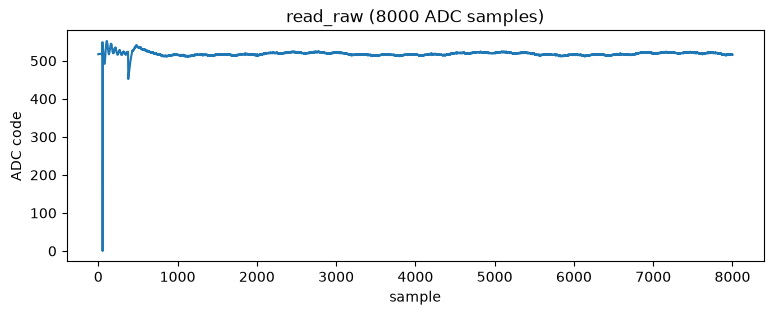

In [85]:
_, raw = grab('raw', 'raw')
send(f'dac write {100}')
reply = ''.join(b.decode('utf-8', 'replace') for b in probe.set_one_mux(2)).strip()
print('  data: min/mean/max = %d/%d/%d' % (int(raw.min()), int(raw.mean()), int(raw.max())))
plt.figure(figsize=(9, 3)); plt.plot(raw)
plt.title('read_raw (8000 ADC samples)'); plt.xlabel('sample'); plt.ylabel('ADC code'); plt.show()

## 9. `read_fft` — 4096-sample Hilbert envelope

After the capture, the `status` breakdown shows the **per-stage DSP µs** for the
frame that just ran.

Pico reply: OK capture started type=envelope samples=4096
  header: samples=4096 bytes=16384 dc_mean=515.7 envelope_peak=1045.9 seq=315
  saved -> data/dsp_captures/envelope (envelope.npy, header.json, status.txt)

ultr4rick status
  board/package    ultr4rick / RP2350B
  firmware         0.1.15
  dsp backend      f32-rfft-hilbert
  cmsis-dsp        1.17.0
  acquisition      4096 samples @ 60 MS/s
  pulser           armed
  pulse (ns)       neg 96 / damp 6000 / pos 96, neg-first
  dac / scale      100 / 512.0
  stream           off @ 0 Hz
  dropped frames   0
  DSP stage times (us):
      preprocess   534
      forward_fft  2263
      mask         149
      inverse_fft  2566
      magnitude    1038
      alaw         0
  dsp_us / worst   6550 / 7322 (over-budget)
  max rates (Hz)   envelope 50, alaw 70


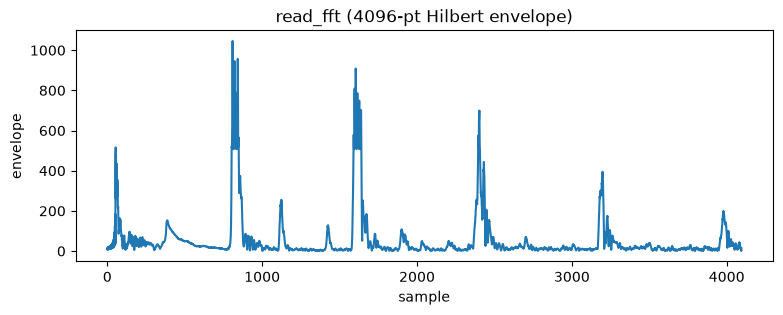

In [86]:
_, env = grab('envelope', 'envelope')
print()
print(dsp.describe_status(probe.status()))
plt.figure(figsize=(9, 3)); plt.plot(env)
plt.title('read_fft (4096-pt Hilbert envelope)'); plt.xlabel('sample'); plt.ylabel('envelope'); plt.show()

## 10. A-law — compressed envelope

`acq alaw` returns the envelope A-law-compressed to `uint8`. Decode it back to
ADC-count amplitude with `dsp.alaw_decode(bytes, reference)` and overlay it on
the float Hilbert envelope from step 9 — they should track closely.

Pico reply: OK capture started type=alaw
  header: samples=4096 bytes=4096 dc_mean=516.1 envelope_peak=1045.2 seq=316
  saved -> data/dsp_captures/alaw (alaw.npy, header.json, status.txt)
  alaw uint8 min/max = 1/255  reference=512.0


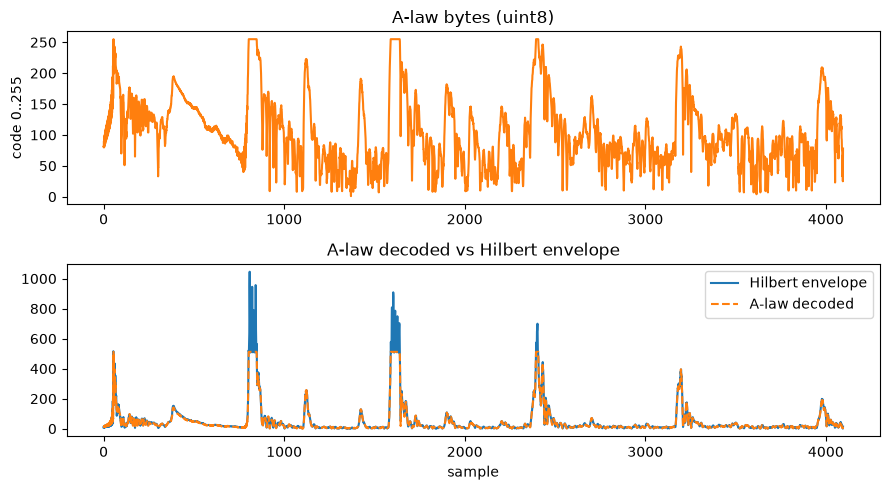

In [87]:
alaw_frame, alaw = grab('alaw', 'alaw')
reference = alaw_frame.header.alaw_reference
decoded = dsp.alaw_decode(alaw, reference)
print('  alaw uint8 min/max = %d/%d  reference=%.1f' % (int(alaw.min()), int(alaw.max()), reference))
fig, ax = plt.subplots(2, 1, figsize=(9, 5))
ax[0].plot(alaw, color='tab:orange'); ax[0].set_title('A-law bytes (uint8)'); ax[0].set_ylabel('code 0..255')
ax[1].plot(env, label='Hilbert envelope')
ax[1].plot(decoded, '--', label='A-law decoded')
ax[1].set_title('A-law decoded vs Hilbert envelope'); ax[1].set_xlabel('sample'); ax[1].legend()
fig.tight_layout(); plt.show()

## 11. DSP self-test

`dsp selftest` streams deterministic synthetic vectors (7 cases x raw/envelope/
alaw) — a firmware-only check of the DSP pipeline. We read the frames directly
with a `FrameReader`.

In [88]:
probe.ser.reset_input_buffer()
probe.ser.write(b'dsp selftest\n')
ok = probe.ser.readline().decode('utf-8', 'replace').strip()
print('Pico reply:', ok)
n = int(re.search(r'frames=(\d+)', ok).group(1))
reader = dsp.FrameReader(probe.ser)
frames = [reader.read_frame() for _ in range(n)]
print('read %d self-test frames' % len(frames))
for f in frames:
    if f.header.payload_name == 'envelope':
        print('  case %d %-10s envelope_peak=%.1f'
              % (f.header.selftest_case, dsp.SELFTEST_NAMES[f.header.selftest_case]
                 if f.header.selftest_case < len(dsp.SELFTEST_NAMES) else '?', f.header.envelope_peak))

Pico reply: OK selftest frames=21 cases=7
read 21 self-test frames
  case 0 zero       envelope_peak=0.0
  case 1 dc         envelope_peak=0.0
  case 2 sinusoid   envelope_peak=200.7
  case 3 am         envelope_peak=314.0
  case 4 two-bursts envelope_peak=359.1
  case 5 impulse    envelope_peak=510.9
  case 6 clipping   envelope_peak=1276.7


## 12. Pulser order check

Capture a raw trace with each polarity order and compare the transmit region.

pulse config 96 6000 96 pos-first -> OK pulse=96/6000/96/pos-first
pulse config 96 6000 96 neg-first -> OK pulse=96/6000/96/neg-first


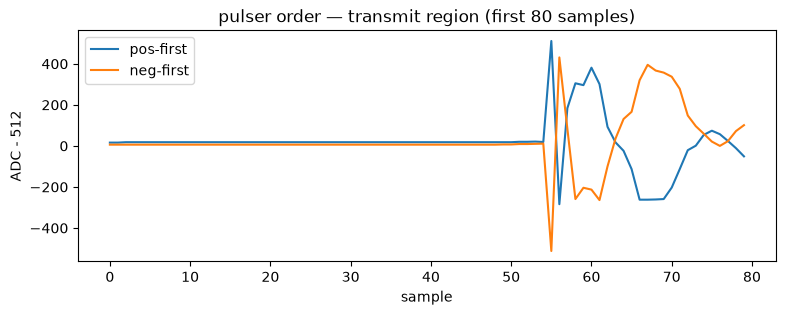

In [89]:
send('pulse config 96 6000 96 pos-first')
raw_pos = probe.read_raw().samples().astype(int) - 512
send('pulse config 96 6000 96 neg-first')
raw_neg = probe.read_raw().samples().astype(int) - 512
plt.figure(figsize=(9, 3))
plt.plot(raw_pos[:80], label='pos-first')
plt.plot(raw_neg[:80], label='neg-first')
plt.title('pulser order — transmit region (first 80 samples)')
plt.xlabel('sample'); plt.ylabel('ADC - 512'); plt.legend(); plt.show()

## 13. Mux: transmit/receive on element 2, then on element 4

The MAX14866 switches are used in pairs: element *k* (1..8) goes to RX (`ECHO_IN`) through SW(2k-2) and to TX
(pulser) through SW(2k-1). `probe.set_one_mux(k)` closes both switches of element *k* and opens all others
(element 2 -> `0x000C`, element 4 -> `0x00C0`). Any other pattern can be loaded with
`probe.write_mux(0x....)`. The pulser is still armed from step 6, so each capture transmits on the selected
element. The first capture after a mux change is discarded (start-of-frame transient). The mux is cleared at the
end.

element 1 -> mux 0x0003 | Pico reply: OK mux=0003
Pico reply: OK capture started type=raw samples=8000
  header: samples=8000 bytes=16000 dc_mean=515.4 envelope_peak=0.0 seq=341
  saved -> data/dsp_captures/mux_e1 (raw.npy, header.json, status.txt)
Pico reply: OK capture started type=envelope samples=4096
  header: samples=4096 bytes=16384 dc_mean=513.0 envelope_peak=668.4 seq=342
  saved -> data/dsp_captures/mux_e1 (envelope.npy, header.json, status.txt)
element 2 -> mux 0x000C | Pico reply: OK mux=000C
Pico reply: OK capture started type=raw samples=8000
  header: samples=8000 bytes=16000 dc_mean=516.7 envelope_peak=0.0 seq=344
  saved -> data/dsp_captures/mux_e2 (raw.npy, header.json, status.txt)
Pico reply: OK capture started type=envelope samples=4096
  header: samples=4096 bytes=16384 dc_mean=515.7 envelope_peak=1000.7 seq=345
  saved -> data/dsp_captures/mux_e2 (envelope.npy, header.json, status.txt)
element 3 -> mux 0x0030 | Pico reply: OK mux=0030
Pico reply: OK capture starte

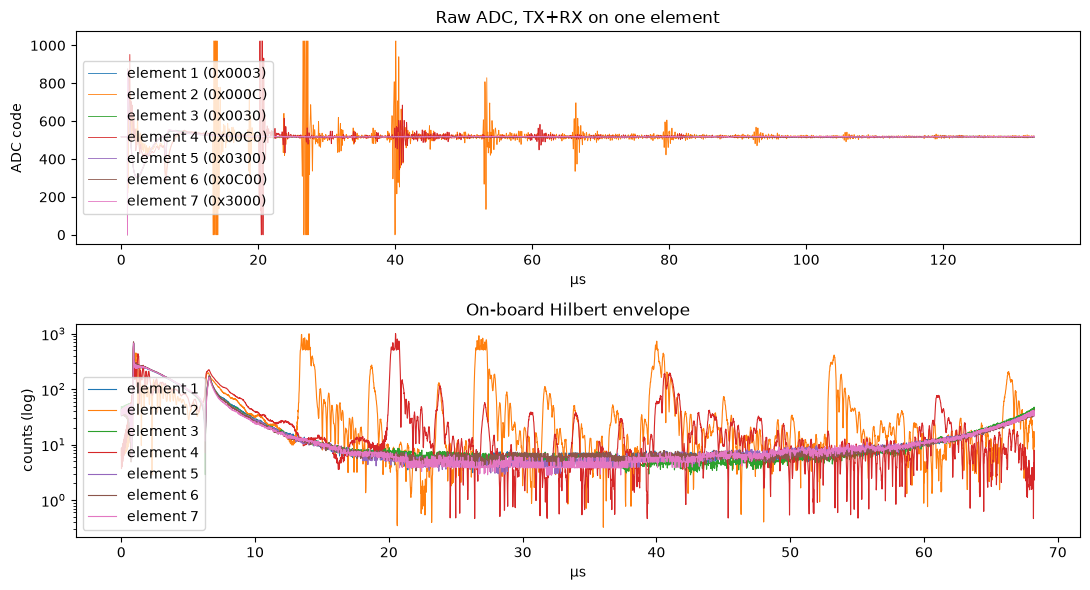

In [90]:
FS_MHZ = 60.0
MUX_ELEMENTS = [x+1 for x in range(7)]                       # TX+RX pairs to compare (1..8)

mux_raw, mux_env = {}, {}
try:
    for k in MUX_ELEMENTS:
        reply = ''.join(b.decode('utf-8', 'replace') for b in probe.set_one_mux(k)).strip()
        print('element %d -> mux 0x%04X | Pico reply: %s' % (k, Ultr4rick.mux_element_mask(k), reply))
        probe.read_raw()                    # discard: transient after the switch change
        _, mux_raw[k] = grab('raw', f'mux_e{k}')
        _, mux_env[k] = grab('envelope', f'mux_e{k}')
finally:
    print(''.join(b.decode('utf-8', 'replace') for b in probe.clear_mux()).strip())

fig, ax = plt.subplots(2, 1, figsize=(11, 6))
for k in MUX_ELEMENTS:
    r = mux_raw[k].astype(float)
    e = mux_env[k]
    ax[0].plot(np.arange(len(r)) / FS_MHZ, r, lw=.6, label=f'element {k} (0x{Ultr4rick.mux_element_mask(k):04X})')
    ax[1].plot(np.arange(len(e)) / FS_MHZ, e, lw=.8, label=f'element {k}')
ax[0].set_title('Raw ADC, TX+RX on one element'); ax[0].set_xlabel('µs'); ax[0].set_ylabel('ADC code'); ax[0].legend()
ax[1].set_yscale('log'); ax[1].set_title('On-board Hilbert envelope')
ax[1].set_xlabel('µs'); ax[1].set_ylabel('counts (log)'); ax[1].legend()
fig.tight_layout()
os.makedirs('data', exist_ok=True)
fig.savefig('data/mux_elements.png', dpi=100)
plt.show()

## 14. Saved files

In [91]:
for root, _, files in sorted(os.walk(CAPT)):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print('%8d  %s' % (os.path.getsize(p), p))

    4224  data/dsp_captures/alaw/alaw.npy
     403  data/dsp_captures/alaw/header.json
     600  data/dsp_captures/alaw/status.txt
   16512  data/dsp_captures/envelope/envelope.npy
     405  data/dsp_captures/envelope/header.json
     598  data/dsp_captures/envelope/status.txt
   16512  data/dsp_captures/mux_e1/envelope.npy
     405  data/dsp_captures/mux_e1/header.json
   16128  data/dsp_captures/mux_e1/raw.npy
     598  data/dsp_captures/mux_e1/status.txt
   16512  data/dsp_captures/mux_e2/envelope.npy
     404  data/dsp_captures/mux_e2/header.json
   16128  data/dsp_captures/mux_e2/raw.npy
     598  data/dsp_captures/mux_e2/status.txt
   16512  data/dsp_captures/mux_e3/envelope.npy
     405  data/dsp_captures/mux_e3/header.json
   16128  data/dsp_captures/mux_e3/raw.npy
     598  data/dsp_captures/mux_e3/status.txt
   16512  data/dsp_captures/mux_e4/envelope.npy
     402  data/dsp_captures/mux_e4/header.json
   16128  data/dsp_captures/mux_e4/raw.npy
     598  data/dsp_captures/mux_

## 15. Idle vs pulsed capture (comparison figure)

Takes an idle reference with the pulser **disarmed**, then **arms** it for one raw + one envelope capture and
**disarms** it again (also on error). Plots the full raw trace, a zoom on the first 15 µs (excitation +
damping), and the on-board Hilbert envelope on a log scale. The figure is saved to `data/pulsed_capture.png`.
Lower `GAIN` if the echoes clip at 0/1023.

armed flag in header: True | pulse 96 6000 96
raw pulsed min/mean/max 60/517.8/523 | idle std 0.9
envelope max 433.6 at 0.90 us | idle max 3.3


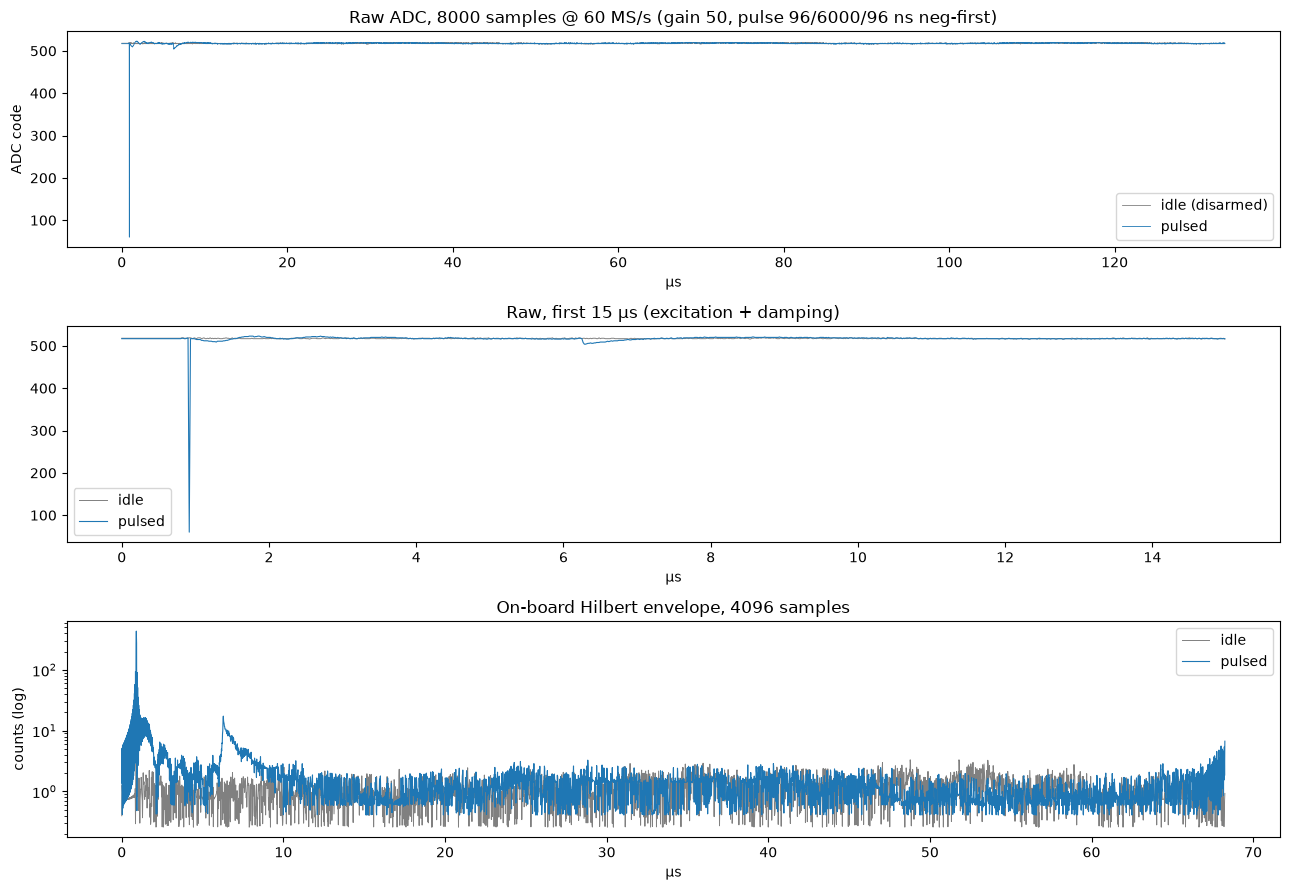

In [92]:
GAIN = 50                                   # TGC DAC 0..1023; 300 saturates the echoes
PULSE = (96, 6000, 96, 'neg-first')         # negative_ns, damp_ns, positive_ns, order
FS_MHZ = 60.0

probe.command(f'dac write {GAIN}')
probe.command('pulse config %d %d %d %s' % PULSE)
probe.disarm_pulser()
probe.read_raw()                            # discard: first capture after idle has a transient
idle_raw = probe.read_raw().samples().astype(float)
idle_env = probe.read_fft().samples()
try:
    probe.command('pulser arm')
    raw_f, env_f = probe.read_raw(), probe.read_fft()
finally:
    #print(probe.command('pulser disarm'))
    pass
pulsed_raw = raw_f.samples().astype(float)
pulsed_env = env_f.samples()
print('armed flag in header:', bool(raw_f.header.flags & dsp.FLAG_PULSER_ARMED),
      '| pulse', raw_f.header.negative_ns, raw_f.header.damp_ns, raw_f.header.positive_ns)

t = np.arange(len(pulsed_raw)) / FS_MHZ
te = np.arange(len(pulsed_env)) / FS_MHZ
print('raw pulsed min/mean/max %.0f/%.1f/%.0f | idle std %.1f'
      % (pulsed_raw.min(), pulsed_raw.mean(), pulsed_raw.max(), idle_raw.std()))
print('envelope max %.1f at %.2f us | idle max %.1f'
      % (pulsed_env.max(), te[pulsed_env.argmax()], idle_env.max()))

fig, ax = plt.subplots(3, 1, figsize=(13, 9))
ax[0].plot(t, idle_raw, lw=.6, color='gray', label='idle (disarmed)')
ax[0].plot(t, pulsed_raw, lw=.6, label='pulsed')
ax[0].set_title('Raw ADC, %d samples @ 60 MS/s (gain %d, pulse %d/%d/%d ns %s)'
                % ((len(pulsed_raw), GAIN) + PULSE))
ax[0].set_xlabel('µs'); ax[0].set_ylabel('ADC code'); ax[0].legend()
z = int(15 * FS_MHZ)
ax[1].plot(t[:z], idle_raw[:z], lw=.7, color='gray', label='idle')
ax[1].plot(t[:z], pulsed_raw[:z], lw=.8, label='pulsed')
ax[1].set_title('Raw, first 15 µs (excitation + damping)'); ax[1].set_xlabel('µs'); ax[1].legend()
ax[2].plot(te, idle_env, lw=.7, color='gray', label='idle')
ax[2].plot(te, pulsed_env, lw=.8, label='pulsed')
ax[2].set_yscale('log'); ax[2].set_title('On-board Hilbert envelope, %d samples' % len(pulsed_env))
ax[2].set_xlabel('µs'); ax[2].set_ylabel('counts (log)'); ax[2].legend()
fig.tight_layout()
os.makedirs('data', exist_ok=True)
fig.savefig('data/pulsed_capture.png', dpi=100)
plt.show()

## 16. Disarm the pulser

In [93]:
#send('pulser disarm')

---
Send `probe.help()` for the full command set, `ultr4rick.dsp` for the
protocol, and `python/example_dsp.py` for a script version. A-law needs
`dsp.SELFTEST_NAMES` / `alaw_decode` from `ultr4rick.dsp`.